In [1]:
# ==========================================================
# STEP 1: Select Forecasting Algorithm
# ==========================================================
# Algorithm Chosen:
# SVR (Support Vector Regression)
# ==========================================================

In [4]:
# ==========================================================
# STEP 2: Import Required Libraries
# ==========================================================

# Download stock market data
import yfinance as yf

# Data manipulation and analysis
import pandas as pd

# Mathematical operations
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Support Vector Regression model
from sklearn.svm import SVR

# Feature scaling
from sklearn.preprocessing import StandardScaler

# Performance evaluation metric
from sklearn.metrics import mean_squared_error

# RSI technical indicator
from ta.momentum import RSIIndicator

# MACD technical indicator
from ta.trend import MACD

In [5]:
# ==========================================================
# STEP 3: Download Historical Stock Dataset
# ==========================================================
# Download TCS stock data
# Time Period: 2020 - 2025
# Data Source: Yahoo Finance
# ==========================================================

data = yf.download(
    "TCS.NS",
    start="2020-01-01",
    end="2025-12-31"
)

print("Dataset Downloaded Successfully")

[*********************100%***********************]  1 of 1 completed

Dataset Downloaded Successfully


In [6]:
# ==========================================================
# STEP 4: Display Raw Dataset
# ==========================================================
# Display complete downloaded dataset
# ==========================================================

print(data)

Price             Close         High          Low         Open   Volume
Ticker           TCS.NS       TCS.NS       TCS.NS       TCS.NS   TCS.NS
Date                                                                   
2020-01-01  1831.109619  1844.879101  1819.620752  1831.447442  1354908
2020-01-02  1822.703857  1841.542124  1815.565647  1841.542124  2380752
2020-01-03  1859.029297  1877.909850  1828.068787  1828.068787  4655761
2020-01-06  1858.860352  1880.401827  1848.258525  1862.704068  3023209
2020-01-07  1863.421997  1870.855752  1844.794917  1858.902429  2429317
...                 ...          ...          ...          ...      ...
2025-12-23  3189.922607  3199.463369  3174.021181  3199.463369  2365420
2025-12-24  3198.596191  3206.402441  3176.527032  3184.236815  1367708
2025-12-26  3161.010986  3199.559901  3153.108506  3192.910307  1176664
2025-12-29  3133.544678  3168.720560  3125.256568  3161.010777  2079473
2025-12-30  3129.015381  3148.964397  3121.980157  3132.099247  

In [7]:
# ==========================================================
# STEP 5: Display First Five Records
# ==========================================================
# Preview first five rows
# ==========================================================

data.head()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2020-01-01,1831.109619,1844.879101,1819.620752,1831.447442,1354908
2020-01-02,1822.703857,1841.542124,1815.565647,1841.542124,2380752
2020-01-03,1859.029297,1877.909850,1828.068787,1828.068787,4655761
2020-01-06,1858.860352,1880.401827,1848.258525,1862.704068,3023209
2020-01-07,1863.421997,1870.855752,1844.794917,1858.902429,2429317


In [8]:
# ==========================================================
# STEP 6: Display Last Five Records
# ==========================================================
# Preview last five rows
# ==========================================================

data.tail()

Price,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2025-12-23,3189.922607,3199.463369,3174.021181,3199.463369,2365420
2025-12-24,3198.596191,3206.402441,3176.527032,3184.236815,1367708
2025-12-26,3161.010986,3199.559901,3153.108506,3192.910307,1176664
2025-12-29,3133.544678,3168.720560,3125.256568,3161.010777,2079473
2025-12-30,3129.015381,3148.964397,3121.980157,3132.099247,2807593


In [9]:
# ==========================================================
# STEP 7: Inspect Dataset Structure
# ==========================================================
# Displays:
# - Number of rows
# - Number of columns
# - Data types
# - Non-null values
# ==========================================================

data.info()


<class 'pandas.DataFrame'>
DatetimeIndex: 1486 entries, 2020-01-01 to 2025-12-30
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, TCS.NS)   1486 non-null   float64
 1   (High, TCS.NS)    1486 non-null   float64
 2   (Low, TCS.NS)     1486 non-null   float64
 3   (Open, TCS.NS)    1486 non-null   float64
 4   (Volume, TCS.NS)  1486 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 69.7 KB


In [10]:
# ==========================================================
# STEP 8: Check Missing Values
# ==========================================================
# Check missing values in each column
# ==========================================================

print(data.isnull().sum())

Price   Ticker
Close   TCS.NS    0
High    TCS.NS    0
Low     TCS.NS    0
Open    TCS.NS    0
Volume  TCS.NS    0
dtype: int64


In [11]:
# ==========================================================
# STEP 9: Display Dataset Dimensions
# ==========================================================
# Shape = (Rows, Columns)
# ==========================================================

print("Dataset Shape:", data.shape)


Dataset Shape: (1486, 5)


In [12]:
# ==========================================================
# STEP 10: Select Required Columns
# ==========================================================
# Select OHLCV data:
# Open, High, Low, Close and Volume
# ==========================================================

data = data[['Open', 'High', 'Low', 'Close', 'Volume']]

data.head()


Price,Open,High,Low,Close,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,
2020-01-01,1831.447442,1844.879101,1819.620752,1831.109619,1354908
2020-01-02,1841.542124,1841.542124,1815.565647,1822.703857,2380752
2020-01-03,1828.068787,1877.909850,1828.068787,1859.029297,4655761
2020-01-06,1862.704068,1880.401827,1848.258525,1858.860352,3023209
2020-01-07,1858.902429,1870.855752,1844.794917,1863.421997,2429317


In [13]:
# ==========================================================
# STEP 11: Handle Missing Values
# ==========================================================
# Forward Fill method is used to
# fill missing values.
# ==========================================================

data = data.ffill()

print(data.isnull().sum())

Price   Ticker
Open    TCS.NS    0
High    TCS.NS    0
Low     TCS.NS    0
Close   TCS.NS    0
Volume  TCS.NS    0
dtype: int64


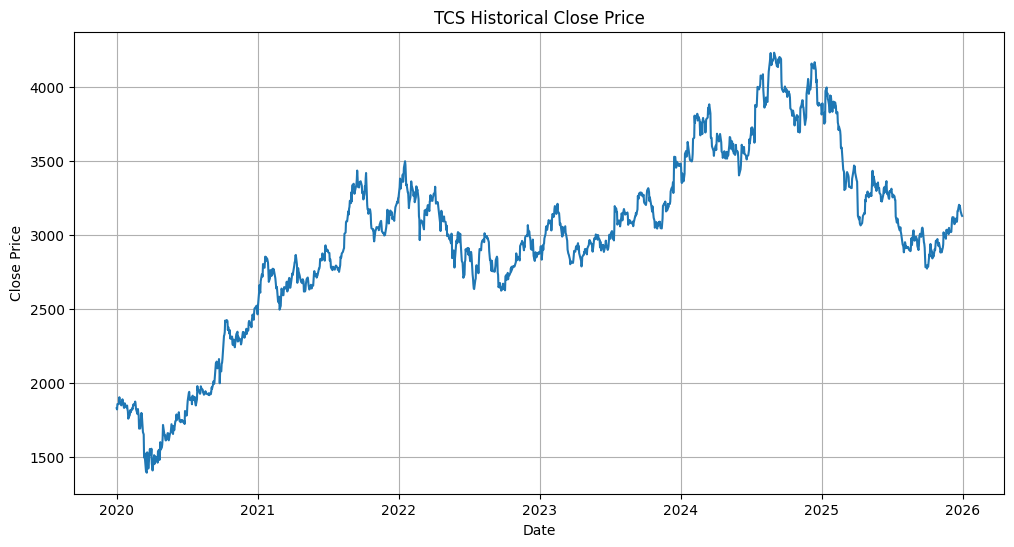

In [14]:
# ==========================================================
# STEP 12: Visualize Historical Stock Prices
# ==========================================================
# Plot historical TCS closing prices
# ==========================================================

plt.figure(figsize=(12,6))

plt.plot(data['Close'])

plt.title("TCS Historical Close Price")

plt.xlabel("Date")

plt.ylabel("Close Price")

plt.grid(True)

plt.show()


In [15]:
# ==========================================================
# STEP 13: Create Lag Features
# ==========================================================
# Lag features use previous closing prices
# to help predict the current closing price.
#
# Lag1  -> Previous day's closing price
# Lag2  -> Closing price two days before
# Lag3  -> Closing price three days before
# Lag5  -> Closing price five days before
# Lag10 -> Closing price ten days before
# ==========================================================

data['Close_Lag1'] = data['Close'].shift(1)

data['Close_Lag2'] = data['Close'].shift(2)

data['Close_Lag3'] = data['Close'].shift(3)

data['Close_Lag5'] = data['Close'].shift(5)

data['Close_Lag10'] = data['Close'].shift(10)

data.head(15)


Price,Open,High,Low,Close,Volume,Close_Lag1,Close_Lag2,Close_Lag3,Close_Lag5,Close_Lag10
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS,,,,,
Date,,,,,,,,,,
2020-01-01,1831.447442,1844.879101,1819.620752,1831.109619,1354908,NaN,NaN,NaN,NaN,NaN
2020-01-02,1841.542124,1841.542124,1815.565647,1822.703857,2380752,1831.109619,NaN,NaN,NaN,NaN
2020-01-03,1828.068787,1877.909850,1828.068787,1859.029297,4655761,1822.703857,1831.109619,NaN,NaN,NaN
2020-01-06,1862.704068,1880.401827,1848.258525,1858.860352,3023209,1859.029297,1822.703857,1831.109619,NaN,NaN
2020-01-07,1858.902429,1870.855752,1844.794917,1863.421997,2429317,1858.860352,1859.029297,1822.703857,NaN,NaN
2020-01-08,1862.703825,1909.165826,1860.211814,1905.153198,5197454,1863.421997,1858.860352,1859.029297,1831.109619,NaN
2020-01-09,1899.662327,1902.365530,1866.927735,1870.602539,3734173,1905.153198,1863.421997,1858.860352,1822.703857,NaN
2020-01-10,1882.133061,1887.201642,1865.237791,1869.926270,1915807,1870.602539,1905.153198,1863.421997,1859.029297,NaN


In [16]:
# ==========================================================
# STEP 14: Create Moving Average Features
# ==========================================================
# Moving averages are used to identify
# price trends.
#
# MA5  -> 5-day moving average
# MA10 -> 10-day moving average
# MA20 -> 20-day moving average
# ==========================================================

data['MA5'] = data['Close'].rolling(5).mean()

data['MA10'] = data['Close'].rolling(10).mean()

data['MA20'] = data['Close'].rolling(20).mean()

data.head(20)


Price,Open,High,Low,Close,Volume,Close_Lag1,Close_Lag2,Close_Lag3,Close_Lag5,Close_Lag10,MA5,MA10,MA20
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS,,,,,,,,
Date,,,,,,,,,,,,,
2020-01-01,1831.447442,1844.879101,1819.620752,1831.109619,1354908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,1841.542124,1841.542124,1815.565647,1822.703857,2380752,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,1828.068787,1877.909850,1828.068787,1859.029297,4655761,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,1862.704068,1880.401827,1848.258525,1858.860352,3023209,1859.029297,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN
2020-01-07,1858.902429,1870.855752,1844.794917,1863.421997,2429317,1858.860352,1859.029297,1822.703857,NaN,NaN,1847.025024,NaN,NaN
2020-01-08,1862.703825,1909.165826,1860.211814,1905.153198,5197454,1863.421997,1858.860352,1859.029297,1831.109619,NaN,1861.833740,NaN,NaN
2020-01-09,1899.662327,1902.365530,1866.927735,1870.602539,3734173,1905.153198,1863.421997,1858.860352,1822.703857,NaN,1871.413477,NaN,NaN
2020-01-10,1882.133061,1887.201642,1865.237791,1869.926270,1915807,1870.602539,1905.153198,1863.421997,1859.029297,NaN,1873.592871,NaN,NaN


In [18]:
# ==========================================================
# STEP 15: Calculate RSI Indicator
# ==========================================================
# RSI (Relative Strength Index) measures
# the strength and momentum of price movements.
# ==========================================================

if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

rsi = RSIIndicator(
    close=data['Close']
)

data['RSI'] = rsi.rsi()

data.head(25)

Price,Open,High,Low,Close,Volume,Close_Lag1,Close_Lag2,Close_Lag3,Close_Lag5,Close_Lag10,MA5,MA10,MA20,RSI
Date,,,,,,,,,,,,,,
2020-01-01,1831.447442,1844.879101,1819.620752,1831.109619,1354908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,1841.542124,1841.542124,1815.565647,1822.703857,2380752,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,1828.068787,1877.909850,1828.068787,1859.029297,4655761,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,1862.704068,1880.401827,1848.258525,1858.860352,3023209,1859.029297,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,1858.902429,1870.855752,1844.794917,1863.421997,2429317,1858.860352,1859.029297,1822.703857,NaN,NaN,1847.025024,NaN,NaN,NaN
2020-01-08,1862.703825,1909.165826,1860.211814,1905.153198,5197454,1863.421997,1858.860352,1859.029297,1831.109619,NaN,1861.833740,NaN,NaN,NaN
2020-01-09,1899.662327,1902.365530,1866.927735,1870.602539,3734173,1905.153198,1863.421997,1858.860352,1822.703857,NaN,1871.413477,NaN,NaN,NaN
2020-01-10,1882.133061,1887.201642,1865.237791,1869.926270,1915807,1870.602539,1905.153198,1863.421997,1859.029297,NaN,1873.592871,NaN,NaN,NaN
2020-01-13,1873.559372,1874.488489,1845.555330,1850.328369,2843893,1869.926270,1870.602539,1905.153198,1858.860352,NaN,1871.886475,NaN,NaN,NaN


In [19]:
# ==========================================================
# STEP 16: Calculate MACD Indicator
# ==========================================================
# MACD (Moving Average Convergence Divergence) is used
# to identify trends and momentum in stock prices.
# ==========================================================

macd = MACD(
    close=data['Close']
)

data['MACD'] = macd.macd()

data.head(25)

Price,Open,High,Low,Close,Volume,Close_Lag1,Close_Lag2,Close_Lag3,Close_Lag5,Close_Lag10,MA5,MA10,MA20,RSI,MACD
Date,,,,,,,,,,,,,,,
2020-01-01,1831.447442,1844.879101,1819.620752,1831.109619,1354908,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-02,1841.542124,1841.542124,1815.565647,1822.703857,2380752,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-03,1828.068787,1877.909850,1828.068787,1859.029297,4655761,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-06,1862.704068,1880.401827,1848.258525,1858.860352,3023209,1859.029297,1822.703857,1831.109619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-07,1858.902429,1870.855752,1844.794917,1863.421997,2429317,1858.860352,1859.029297,1822.703857,NaN,NaN,1847.025024,NaN,NaN,NaN,NaN
2020-01-08,1862.703825,1909.165826,1860.211814,1905.153198,5197454,1863.421997,1858.860352,1859.029297,1831.109619,NaN,1861.833740,NaN,NaN,NaN,NaN
2020-01-09,1899.662327,1902.365530,1866.927735,1870.602539,3734173,1905.153198,1863.421997,1858.860352,1822.703857,NaN,1871.413477,NaN,NaN,NaN,NaN
2020-01-10,1882.133061,1887.201642,1865.237791,1869.926270,1915807,1870.602539,1905.153198,1863.421997,1859.029297,NaN,1873.592871,NaN,NaN,NaN,NaN
2020-01-13,1873.559372,1874.488489,1845.555330,1850.328369,2843893,1869.926270,1870.602539,1905.153198,1858.860352,NaN,1871.886475,NaN,NaN,NaN,NaN


In [20]:
# ==========================================================
# STEP 17: Remove Missing Values
# ==========================================================
# Missing values are generated due to lag features,
# moving averages, RSI and MACD calculations.
# ==========================================================

data = data.dropna()

print(data.isnull().sum())

data.head()

Price
Open           0
High           0
Low            0
Close          0
Volume         0
Close_Lag1     0
Close_Lag2     0
Close_Lag3     0
Close_Lag5     0
Close_Lag10    0
MA5            0
MA10           0
MA20           0
RSI            0
MACD           0
dtype: int64


Price,Open,High,Low,Close,Volume,Close_Lag1,Close_Lag2,Close_Lag3,Close_Lag5,Close_Lag10,MA5,MA10,MA20,RSI,MACD
Date,,,,,,,,,,,,,,,
2020-02-05,1790.732333,1826.038930,1781.672878,1817.445190,2439322,1784.593628,1780.148804,1760.294189,1824.261108,1864.308472,1790.512085,1816.611121,1840.005927,46.793406,-14.041836
2020-02-06,1816.132571,1840.855639,1791.155456,1802.035400,2640065,1817.445190,1784.593628,1780.148804,1810.078613,1855.038208,1788.903442,1811.310840,1836.577570,43.630050,-14.162854
2020-02-07,1811.052234,1821.212415,1794.118599,1808.977905,2083442,1802.035400,1817.445190,1784.593628,1760.294189,1848.645264,1798.640186,1807.344104,1833.530151,45.420240,-13.542450
2020-02-10,1812.661312,1834.759794,1794.119060,1830.484009,2383032,1808.977905,1802.035400,1817.445190,1780.148804,1836.664673,1808.707227,1806.726038,1832.537933,50.648772,-11.186462
2020-02-11,1831.373103,1841.363991,1818.334283,1823.244873,1335820,1830.484009,1808.977905,1802.035400,1784.593628,1848.941528,1816.437476,1804.156372,1830.484753,48.948959,-9.790603


In [21]:
# ==========================================================
# STEP 18: Select Input Features and Target Variable
# ==========================================================
# Input features are used to predict the Closing Price.
# The Closing Price is the target variable.
# ==========================================================

features = [
    'Open',
    'High',
    'Low',
    'Volume',
    'Close_Lag1',
    'Close_Lag2',
    'Close_Lag3',
    'Close_Lag5',
    'Close_Lag10',
    'MA5',
    'MA10',
    'MA20',
    'RSI',
    'MACD'
]

X = data[features]

y = data['Close']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
Price              Open         High          Low   Volume   Close_Lag1  \
Date                                                                      
2020-02-05  1790.732333  1826.038930  1781.672878  2439322  1784.593628   
2020-02-06  1816.132571  1840.855639  1791.155456  2640065  1817.445190   
2020-02-07  1811.052234  1821.212415  1794.118599  2083442  1802.035400   
2020-02-10  1812.661312  1834.759794  1794.119060  2383032  1808.977905   
2020-02-11  1831.373103  1841.363991  1818.334283  1335820  1830.484009   

Price        Close_Lag2   Close_Lag3   Close_Lag5  Close_Lag10          MA5  \
Date                                                                          
2020-02-05  1780.148804  1760.294189  1824.261108  1864.308472  1790.512085   
2020-02-06  1784.593628  1780.148804  1810.078613  1855.038208  1788.903442   
2020-02-07  1817.445190  1784.593628  1760.294189  1848.645264  1798.640186   
2020-02-10  1802.035400  1817.445190  1780.148804  1836.664673 

In [22]:
# ==========================================================
# STEP 19: Split Dataset into Training and Testing Sets
# ==========================================================
# The dataset is divided chronologically into
# 80% training data and 20% testing data.
# ==========================================================

split = int(len(X) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1168, 14)
Testing Data: (293, 14)


In [23]:
# ==========================================================
# STEP 20: Scale Input Features and Target Variable
# ==========================================================
# StandardScaler converts the values into a common scale.
# Scaling is important because SVR is sensitive to
# differences in feature ranges.
# ==========================================================

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

print("X Training Shape:", X_train_scaled.shape)
print("X Testing Shape:", X_test_scaled.shape)

X Training Shape: (1168, 14)
X Testing Shape: (293, 14)


In [24]:
# ==========================================================
# STEP 21: Build SVR Model
# ==========================================================
# SVR (Support Vector Regression) is used to predict
# continuous values such as stock prices.
#
# RBF kernel is used to capture nonlinear relationships
# between stock features and the closing price.
# ==========================================================

svr_model = SVR(
    kernel='rbf',
    C=100,
    epsilon=0.01,
    gamma='scale'
)

print(svr_model)

SVR(C=100, epsilon=0.01)


In [25]:
# ==========================================================
# STEP 22: Train SVR Model
# ==========================================================
# The SVR model is trained using the scaled
# training features and target values.
# ==========================================================

svr_model.fit(
    X_train_scaled,
    y_train_scaled
)

print("SVR Model Training Completed")

SVR Model Training Completed


In [26]:
# ==========================================================
# STEP 23: Predict Stock Prices
# ==========================================================
# The trained SVR model is used to predict
# stock closing prices from the testing data.
# ==========================================================

y_pred_scaled = svr_model.predict(
    X_test_scaled
)

y_pred = scaler_y.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

print("Predicted Stock Prices:")
print(y_pred[:10])

Predicted Stock Prices:
[3773.3961929  3801.06993949 3780.80485657 3789.5119051  3727.340883
 3689.51194464 3692.70287302 3673.40341716 3841.03396575 3837.76924919]


In [27]:
# ==========================================================
# STEP 24: Convert Predictions and Calculate RMSE
# ==========================================================
# RMSE (Root Mean Squared Error) measures the difference
# between actual and predicted stock prices.
# Lower RMSE indicates smaller prediction error.
# ==========================================================

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

Mean Squared Error: 776.7750978568656
Root Mean Squared Error: 27.87068527784822


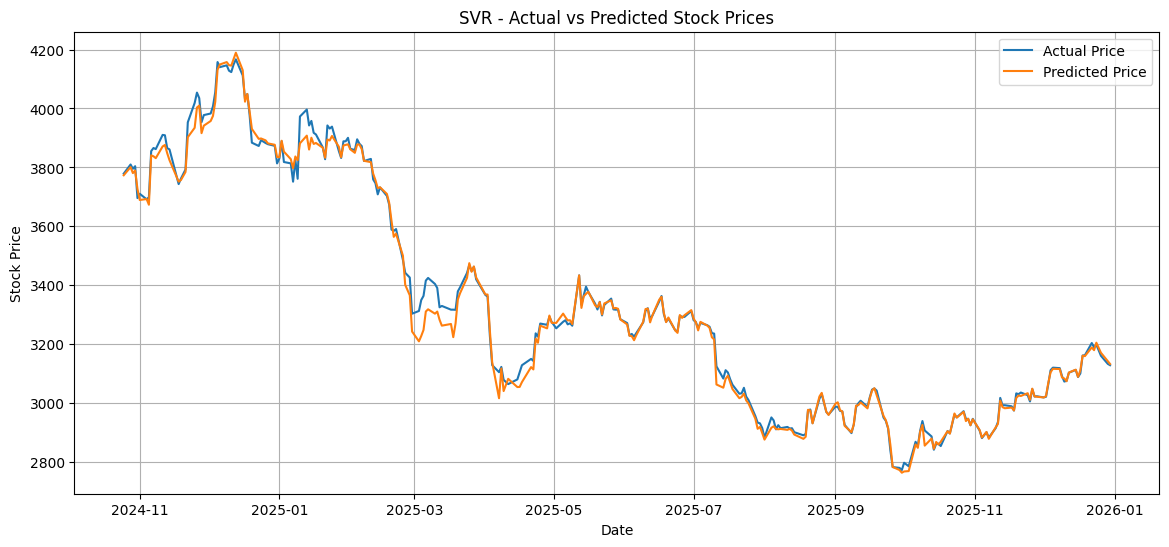

In [28]:
# ==========================================================
# STEP 25: Compare Actual vs Predicted Prices
# ==========================================================
# The actual and predicted stock prices are plotted
# to visually evaluate the performance of the SVR model.
# ==========================================================

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test,
    label='Actual Price'
)

plt.plot(
    y_test.index,
    y_pred,
    label='Predicted Price'
)

plt.title('SVR - Actual vs Predicted Stock Prices')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.legend()
plt.grid(True)

plt.show()